# Shorts vs MV

Question: what kind of content should VELORA post during its debut?

I compare content types (Shorts, MV, dance practice, live, other) by:
- **views per day**
- **likes per day** (YouTube changed how Shorts views are counted in 2025, so likes are a fairer way to compare Shorts with long videos)
- **engagement rate** = (likes + comments) / views

Like the release timing notebook, every video is compared with the normal level of its own group.

In [9]:
import re
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/raw/videos.csv")
df["published_at"] = pd.to_datetime(df["published_at"])
df["collected_at"] = pd.to_datetime(df["collected_at"])

df["days_since"] = (df["collected_at"] - df["published_at"]).dt.days

# last 2 years only, and at least 30 days old
df = df[(df["days_since"] >= 30) & (df["days_since"] <= 730)].copy()
df = df[df["views"] > 0]

print(len(df), "videos")

4898 videos


## 1. Content type

- **Short**: 60 seconds or less
- **MV**: same rule as the release timing notebook
- **Dance practice**: "practice" in the title
- **Live**: live, session, concert or stage
- **Other**: everything else (vlogs, behind the scenes, variety)

In [10]:
mv_words = r"\bm/?v\b|music video"
not_mv_words = r"teaser|react|behind|making|practice|choreography|dance|performance|\blive\b|bts|ver\.|recap|storytelling|world|ep\.|vlog|days? with|ใน mv|การถ่ายทำ|ตามติด|เกาะติด|หนึ่งวัน"


def get_type(row):
    title = row["title"].lower()

    if row["duration_sec"] <= 60:
        return "Short"
    if row["duration_sec"] > 120 and re.search(mv_words, title) and not re.search(not_mv_words, title):
        return "MV"
    if "practice" in title:
        return "Dance practice"
    if "live" in title or "session" in title or "concert" in title or "stage" in title:
        return "Live"
    return "Other"


df["type"] = df.apply(get_type, axis=1)
df["type"].value_counts()

type
Short             4256
Other              493
Live                86
Dance practice      39
MV                  24
Name: count, dtype: int64

Check a few titles from each type.

In [11]:
for t in ["Short", "MV", "Dance practice", "Live", "Other"]:
    print("==", t)
    sample = df[df["type"] == t]
    for title in sample["title"].head(5):
        print("  ", title)

== Short
   [Focus🌧️] Taaom - ที่ปรึกษา 🎤🌺 At #4EVEBuskingที่ปรึกษามาถึงที่ไอคอนสยาม #4EVE #4EVEที่ปรึกษา
   [Focus🌧️] Jorin - ที่ปรึกษา 🎤🌻 At #4EVEBuskingที่ปรึกษามาถึงที่ไอคอนสยาม #4EVE #4EVEที่ปรึกษา
   [Focus🌧️] Mind - ที่ปรึกษา 🎤🌹 At #4EVEBuskingที่ปรึกษามาถึงที่ไอคอนสยาม #4EVE #4EVEที่ปรึกษา
   [Focus🌧️] Punch - ที่ปรึกษา 🎤🌼 At #4EVEBuskingที่ปรึกษามาถึงที่ไอคอนสยาม #4EVE #4EVEที่ปรึกษา
   [Focus🌧️] Fai - ที่ปรึกษา 🎤🤎 At #4EVEBuskingที่ปรึกษามาถึงที่ไอคอนสยาม #4EVE #4EVEที่ปรึกษา
== MV
   4EVE - ที่ปรึกษา | OFFICIAL MV
   4EVE - MY CHAINZ | OFFICIAL MV
   4EVE - เปิ๊ดสะก๊าด | OFFICIAL MV
   4EVE - รับจบ | OFFICIAL MV
   4EVE - Salsa No Drama | OFFICIAL MV
== Dance practice
   4EVE - เหงา...เข้าใจ [ THE TEST OF TIME 2000 ] | Dance Practice
   4EVE - 𝙂𝙞𝙧𝙡𝙨 𝙇𝙞𝙠𝙚 𝙈𝙚 | Dance Practice
   4EVE - Salsa No Drama | Dance Practice
   4EVE - Too Perfect For You (สวย เริ่ด เชิด) | Dance Practice
   4EVE - Snooze | Dance Practice
== Live
   [ 🔴LIVE ] Premiere MV | 4EVE - ที่ปรึกษา 🌧️
   ใคร ๆ 

## 2. Scores

- score = value / median of that group (all its videos). 1.0 = normal for the group

In [12]:
df["views_per_day"] = df["views"] / df["days_since"]
df["likes_per_day"] = df["likes"] / df["days_since"]
df["engagement_rate"] = (df["likes"] + df["comments"]) / df["views"]

df["views_score"] = df["views_per_day"] / df.groupby("group")["views_per_day"].transform("median")
df["likes_score"] = df["likes_per_day"] / df.groupby("group")["likes_per_day"].transform("median")


def summary(data):
    table = data.groupby("type").agg(
        videos=("video_id", "count"),
        views_score=("views_score", "median"),
        likes_score=("likes_score", "median"),
        engagement_rate=("engagement_rate", "median"),
    )
    table["engagement_rate"] = (table["engagement_rate"] * 100).round(2)
    return table.sort_values("likes_score", ascending=False).round(2)


by_type = summary(df)
by_type

,videos,views_score,likes_score,engagement_rate
type,,,,
MV,24,143.84,22.64,1.35
Dance practice,39,4.10,1.71,3.26
Other,493,1.31,1.17,5.26
Short,4256,0.94,0.98,7.00
Live,86,1.45,0.91,3.97


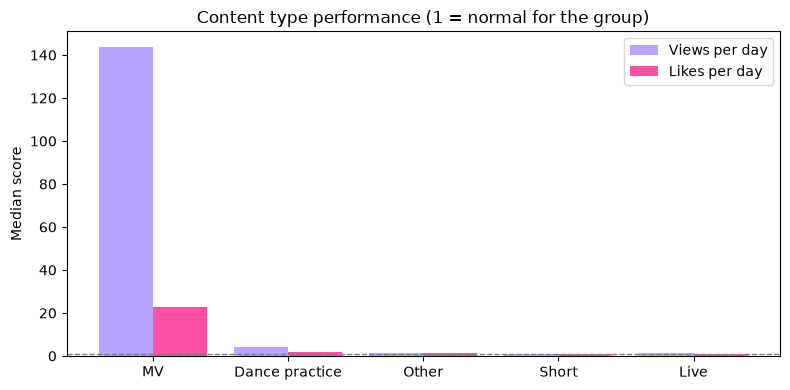

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(by_type))

ax.bar([i - 0.2 for i in x], by_type["views_score"], width=0.4, label="Views per day", color="#B9A4FF")
ax.bar([i + 0.2 for i in x], by_type["likes_score"], width=0.4, label="Likes per day", color="#FF4FA3")
ax.axhline(1, color="gray", linestyle="--", linewidth=1)

ax.set_xticks(list(x))
ax.set_xticklabels(by_type.index)
ax.set_title("Content type performance (1 = normal for the group)")
ax.set_ylabel("Median score")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/content_type.png", dpi=150)
plt.show()

## 3. Check without 4EVE

4EVE has the most videos, so check that the result is the same without it.

In [14]:
summary(df[df["group"] != "4EVE"])

,videos,views_score,likes_score,engagement_rate
type,,,,
MV,12,139.18,42.87,1.84
Dance practice,31,4.25,1.71,3.56
Short,3006,0.98,1.02,7.43
Other,287,1.06,0.84,4.97
Live,58,2.43,0.74,3.19


In [15]:
share = df.groupby("type")[["views", "likes"]].sum()
share = (share / share.sum() * 100).round(1)
share

,views,likes
type,,
Dance practice,3.6,1.9
Live,2.2,1.8
MV,34.7,9.3
Other,10.1,10.8
Short,49.4,76.2


## 4. Content mix of each group

What % of each group's uploads is each type?

In [16]:
mix = pd.crosstab(df["group"], df["type"], normalize="index") * 100
mix.round(0)

type,Dance practice,Live,MV,Other,Short
group,,,,,
4EVE,1.0,2.0,1.0,14.0,83.0
ALALA,0.0,0.0,0.0,11.0,88.0
EMPRESS,0.0,0.0,0.0,5.0,94.0
FELIZZ,1.0,1.0,1.0,12.0,86.0
MXFRUIT,0.0,0.0,11.0,16.0,73.0
PiXXiE,1.0,3.0,0.0,7.0,89.0
Pretzelle,2.0,1.0,2.0,10.0,85.0
VIIS,1.0,1.0,0.0,10.0,88.0


## Findings

**Every group is mainly a Shorts channel.** 87% of videos in the last 2 years are Shorts (73-94% for every group). MVs are only 0.5% of uploads.

**Each content type has a different job:**

| Type | % of uploads | % of views | % of likes |
|---|---|---|---|
| Short | 86.9% | 49.4% | 76.2% |
| MV | 0.5% | 34.7% | 9.3% |
| Dance practice | 0.8% | 3.6% | 1.9% |

- **MV = reach.** Less than 1% of uploads, but one third of all views. One MV gets about 140x the daily views of a normal video, but has the lowest engagement rate (1.4-1.8%)
- **Shorts = fan engagement.** Three quarters of all likes, and the highest engagement rate (7.0-7.4%)
- **Dance practice = the gap.** About 4x the daily views of a normal video, but only 0-2% of uploads for every group
- Per-video results are the same without 4EVE
- Live and Other are mixed groups (concerts, premieres, backstage, busking), so they are not used for the decision

**Decision for VELORA content mix:**
- **1 MV per single** as the main source of reach
- **Shorts as daily content**, around 80-85% of uploads like the market, to keep fans engaged
- **2-3 dance videos per single** (practice, moving ver., fix ver.). Other groups make very few, but they perform well. This also fits the "No Filter" dance challenge plan

**Limitations**
- Shorts are guessed by length (60 seconds or less)
- YouTube changed how Shorts views are counted in 2025, so likes are used as a second check
- Only 24 MVs and 39 dance practice videos in the last 2 years
- Share of views and likes is not checked without 4EVE, so big groups count more in this table
- Content type is based on the title, so some videos may be in the wrong type

In [17]:
df.to_csv("../data/processed/videos_with_type.csv", index=False)
print("saved")

saved
